## Dawn Andrei Pamesa
## Partner: Alba
## TS31

## Decision Trees on the Mushroom Dataset: C4.5 and CHAID

Dataset: mushroom_demo_dataset.csv (500 mushrooms, 8 categorical features, class = edible or poisonous)

## Part 1: C4.5 (Alba)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv('mushroom_demo_dataset.csv')
print(df.shape)
display(df.head())
print(df['class'].value_counts())


(500, 9)


,class,cap_shape,cap_surface,cap_color,bruises,odor,gill_size,stalk_color,habitat
0,edible,bell,fibrous,yellow,no,anise,broad,buff,urban
1,edible,knobbed,fibrous,white,no,almond,broad,brown,grasses
2,poisonous,knobbed,fibrous,white,yes,pungent,narrow,buff,meadows
3,poisonous,bell,grooves,yellow,no,foul,narrow,buff,grasses
4,poisonous,convex,fibrous,brown,no,almond,narrow,yellow,leaves


class
poisonous    353
edible       147
Name: count, dtype: int64


Missing values:


,missing
class,0
cap_shape,0
cap_surface,0
cap_color,0
bruises,0
odor,0
gill_size,0
stalk_color,0
habitat,0


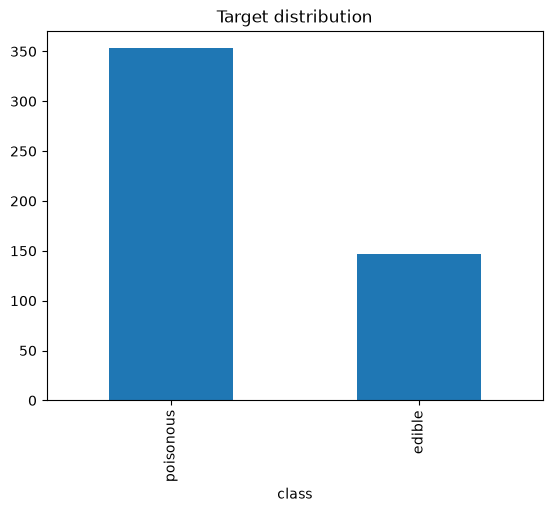

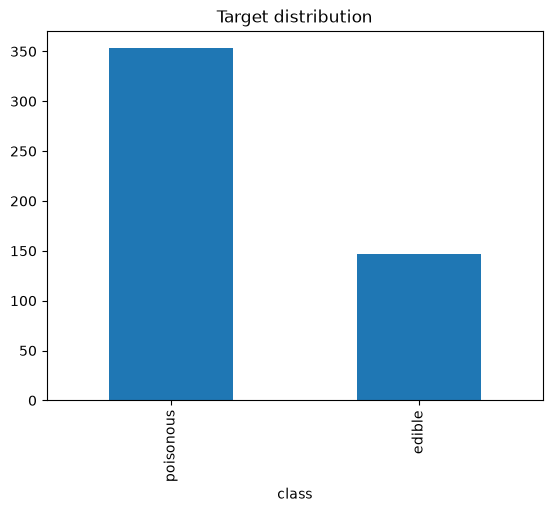

In [2]:

print('Missing values:')
display(df.isna().sum().to_frame('missing'))

display(df['class'].value_counts().plot(kind='bar', title='Target distribution').figure)
plt.show()


In [3]:
def entropy(y):
    probabilities = y.value_counts(normalize=True)
    return -(probabilities * np.log2(probabilities)).sum()

def split_information(values):
    probabilities = pd.Series(values).value_counts(normalize=True)
    return -(probabilities * np.log2(probabilities)).sum()

def gain_ratio(data, feature, target):
    parent_entropy = entropy(data[target])
    weighted_entropy = 0.0
    for _, group in data.groupby(feature, observed=True):
        weighted_entropy += len(group) / len(data) * entropy(group[target])
    information_gain = parent_entropy - weighted_entropy
    si = split_information(data[feature])
    return information_gain / si if si != 0 else 0.0

def majority_class(y):
    return y.mode().iloc[0]

def build_c45(data, features, target, max_depth=None, depth=0, min_samples=2):
    prediction = majority_class(data[target])
    node = {'prediction': prediction, 'samples': len(data)}
    if data[target].nunique() == 1 or not features or len(data) < min_samples:
        node['type'] = 'leaf'
        return node
    if max_depth is not None and depth >= max_depth:
        node['type'] = 'leaf'
        return node
    scores = {feature: gain_ratio(data, feature, target) for feature in features}
    best = max(scores, key=scores.get)
    if scores[best] <= 0:
        node['type'] = 'leaf'
        return node
    node.update({'type':'split', 'feature':best, 'gain_ratio':scores[best], 'branches':{}})
    remaining = [f for f in features if f != best]
    for value, subset in data.groupby(best, observed=True):
        node['branches'][str(value)] = build_c45(subset, remaining, target, max_depth, depth+1, min_samples)
    return node

def predict_c45(tree, row):
    if tree['type'] == 'leaf':
        return tree['prediction']
    value = str(row[tree['feature']])
    child = tree['branches'].get(value)
    return tree['prediction'] if child is None else predict_c45(child, row)

def tree_depth(tree):
    if tree['type'] == 'leaf': return 0
    return 1 + max(tree_depth(child) for child in tree['branches'].values())


In [4]:
target = 'class'
features = [c for c in df.columns if c != target]
train, test = train_test_split(df, test_size=0.25, random_state=42, stratify=df[target])
c45_tree = build_c45(train, features, target, max_depth=8, min_samples=3)
c45_predictions = test.apply(lambda row: predict_c45(c45_tree, row), axis=1)
print('C4.5 depth:', tree_depth(c45_tree))
print('C4.5 accuracy:', round(accuracy_score(test[target], c45_predictions), 4))
print(classification_report(test[target], c45_predictions))


C4.5 depth: 5
C4.5 accuracy: 0.88
              precision    recall  f1-score   support

      edible       0.76      0.86      0.81        37
   poisonous       0.94      0.89      0.91        88

    accuracy                           0.88       125
   macro avg       0.85      0.88      0.86       125
weighted avg       0.89      0.88      0.88       125



C4.5 result
The C4.5 model reached about 88% accuracy on the test set. This means it classified approximately 88 out of every 100 unseen mushrooms correctly. Its tree depth was 5, so the model needed up to five decision levels to classify a record.

The poisonous class had higher precision and recall than the edible class. Recall for poisonous mushrooms is especially important because it measures how many truly poisonous mushrooms were detected. The model detected about 89% of the poisonous test examples.
- Precision: Of the mushrooms predicted as poisonous, the percentage that were actually poisonous.
- Recall: Of all truly poisonous mushrooms, the percentage correctly identified.
- F1-score: A combined measure of precision and recall.
- Support: The number of test examples in each class.


## Part 2: CHAID (Dawn)

This part uses the same train and test split as Part 1, so the two accuracies can be compared.

Install CHAID

In [5]:
!pip install -q CHAID

Imports

In [6]:
from CHAID import Tree

Features and Target

In [7]:
X_train = train.drop('class', axis='columns')
y_train = train['class']

In [8]:
X_test = test.drop('class', axis='columns')
y_test = test['class']

In [9]:
print("Train shape :", X_train.shape)
print("Test shape  :", X_test.shape)

Train shape : (375, 8)
Test shape  : (125, 8)


How CHAID Picks a Split

In [10]:
table = pd.crosstab(X_train['gill_size'], y_train)
table

class,edible,poisonous
gill_size,,
broad,96,85
narrow,14,180


In [11]:
chi2, p, dof, expected = chi2_contingency(table)
print("Chi-square :", chi2)
print("p-value    :", p)

Chi-square : 92.64952824937465
p-value    : 6.242545923421685e-22


In [12]:
for col in X_train.columns:
    chi2, p, dof, expected = chi2_contingency(pd.crosstab(X_train[col], y_train))
    print(col, ": p-value =", p)

cap_shape : p-value = 0.06556384239716458
cap_surface : p-value = 0.5256603924290968
cap_color : p-value = 0.004541269526453685
bruises : p-value = 0.37775266312663636
odor : p-value = 1.436828032555933e-14
gill_size : p-value = 6.242545923421685e-22
stalk_color : p-value = 0.018261127243509347
habitat : p-value = 0.368669301876794


Build the CHAID Tree

In [13]:
train_df = X_train.copy()
train_df['class'] = y_train

In [14]:
independent_variables = dict.fromkeys(X_train.columns, 'nominal')

In [15]:
chaid_tree = Tree.from_pandas_df(train_df, independent_variables, 'class',
                                 alpha_merge=0.05, max_depth=3,
                                 min_parent_node_size=30, min_child_node_size=10)

Tree Output

In [16]:
chaid_tree.print_tree()

([], {'edible': 110.0, 'poisonous': 265.0}, (gill_size, p=2.0566341862812892e-22, score=94.84719508552931, groups=[['broad'], ['narrow']]), dof=1))
|-- (['broad'], {'edible': 96.0, 'poisonous': 85.0}, (odor, p=5.334635859988382e-32, score=144.01700469661546, groups=[['almond', 'anise', 'none'], ['foul'], ['pungent']]), dof=2))
|   |-- (['almond', 'anise', 'none'], {'edible': 92.0, 'poisonous': 6.0}, (stalk_color, p=0.014847988853953834, score=5.934415924567837, groups=[['brown', 'red', 'white', 'gray', 'pink', 'yellow'], ['buff']]), dof=1))
|   |   |-- (['brown', 'red', 'white', 'gray', 'pink', 'yellow'], {'edible': 80.0, 'poisonous': 3.0}, <Invalid Chaid Split> - the max depth has been reached)
|   |   +-- (['buff'], {'edible': 12.0, 'poisonous': 3.0}, <Invalid Chaid Split> - the minimum parent node size threshold has been reached)
|   |-- (['foul'], {'edible': 4.0, 'poisonous': 34.0}, (stalk_color, p=0.018773503899995696, score=5.522491349480969, groups=[['brown', 'gray', 'pink', 're

Train Accuracy

In [17]:
print("Train accuracy :", chaid_tree.accuracy())

Train accuracy : 0.936


Predict the Test Set

In [18]:
predictions = []
for i in range(len(X_test)):
    row = X_test.iloc[i]
    node = chaid_tree.tree_store[0]
    while node.split_variable is not None:
        value = row[node.split_variable]
        children = [n for n in chaid_tree.tree_store if n.parent == node.node_id and value in n.choices]
        if len(children) == 0:
            break
        node = children[0]
    predictions.append(max(node.members, key=node.members.get))

In [19]:
y_pred = pd.Series(predictions, index=y_test.index)

In [20]:
print("Test accuracy :", (y_pred == y_test).mean())

Test accuracy : 0.96


In [21]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      edible       0.97      0.89      0.93        37
   poisonous       0.96      0.99      0.97        88

    accuracy                           0.96       125
   macro avg       0.96      0.94      0.95       125
weighted avg       0.96      0.96      0.96       125



In [22]:
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])

Predicted,edible,poisonous
Actual,,
edible,33,4
poisonous,1,87


Predict a New Mushroom

In [23]:
x_new = pd.Series({'cap_shape': 'bell', 'cap_surface': 'smooth', 'cap_color': 'white', 'bruises': 'yes',
                  'odor': 'none', 'gill_size': 'broad', 'stalk_color': 'red', 'habitat': 'leaves'})

In [24]:
node = chaid_tree.tree_store[0]
while node.split_variable is not None:
    value = x_new[node.split_variable]
    children = [n for n in chaid_tree.tree_store if n.parent == node.node_id and value in n.choices]
    if len(children) == 0:
        break
    node = children[0]
print("Prediction :", max(node.members, key=node.members.get))

Prediction : edible


## Comparison

In [25]:
print("C4.5 test accuracy  :", round(accuracy_score(test['class'], c45_predictions), 4))
print("CHAID test accuracy :", round((y_pred == y_test).mean(), 4))

C4.5 test accuracy  : 0.88
CHAID test accuracy : 0.96


Wrap-Up

CHAID picked gill_size as the root because it had the smallest chi-square p-value (6.24e-22), and odor came next on the broad-gill branch. On the same 375 train and 125 test mushrooms, CHAID reached 96% test accuracy and C4.5 reached 88%. CHAID missed 1 of the 88 poisonous mushrooms (predicted edible) and 4 of the 37 edible ones (predicted poisonous). Recall for poisonous was 0.99 for CHAID and 0.89 for C4.5. This is one split of a small demo dataset, so the gap could change with another split.